## RENDIMIENTO Y CONSUMO ENERGETICO

El presente proyecto tiene como finalidad generar un informe basado en los datos recolectados durante la carga de vehíulos, donde se evaluara principalmente rendimiento energetico.

A continuación, se realiza la consulta de los datos en el contenedor del drive para explorar los datos inicialmente.

In [ ]:
from google.colab import drive
import pandas as pd

# Montar Drive
drive.mount('/content/drive')

# Ruta del archivo
archivo = "/content/drive/MyDrive/MANTENIMIENTOESA/AutonomiaE-SomosA.xlsx"

# Verificar hojas
xls = pd.ExcelFile(archivo)
print("Hojas encontradas:")
print(xls.sheet_names)

# Cargar datos
df_kwh = pd.read_excel(archivo, sheet_name="KwH")
df_km = pd.read_excel(archivo, sheet_name="Km")

print("\nKWH")
display(df_kwh.head())

print("\nKM")
display(df_km.head())


Mounted at /content/drive
Hojas encontradas:
['KwH', 'Km']

KWH


,ID,2021-05-21 00:00:00,2021-05-22 00:00:00,2021-05-23 00:00:00,2021-05-24 00:00:00,2021-05-25 00:00:00,2021-05-26 00:00:00,2021-05-27 00:00:00,2021-05-28 00:00:00,2021-05-29 00:00:00,...,2026-06-13 00:00:00,2026-06-14 00:00:00,2026-06-15 00:00:00,2026-06-16 00:00:00,2026-06-17 00:00:00,2026-06-18 00:00:00,2026-06-19 00:00:00,2026-06-20 00:00:00,2026-06-21 00:00:00,2026-06-22 00:00:00
0,Z91-4800,133.59,167.30,83.91,206.40,220.65,115.68,121.79,182.34,190.12,...,162.80,0.0,103.36,278.22,193.41,79.25,179.50,101.99,157.26,243.80
1,Z91-4801,103.29,170.85,228.20,122.17,176.71,0.00,137.17,7.39,188.68,...,120.33,0.0,177.55,234.11,161.77,182.03,170.50,86.48,0.00,147.17
2,Z91-4802,124.13,111.74,NaN,109.70,189.79,198.68,142.31,177.10,191.16,...,0.00,0.0,0.00,256.27,400.90,0.00,271.87,173.56,315.24,517.21
3,Z91-4803,258.40,158.46,97.12,159.27,132.26,0.00,140.08,0.00,187.10,...,132.33,0.0,0.00,258.19,225.52,184.41,203.49,319.23,197.16,188.12
4,Z91-4804,139.45,168.68,213.70,195.45,181.45,0.00,81.65,71.40,185.45,...,172.73,160.2,187.79,316.44,150.17,249.03,136.50,178.10,134.16,0.00



KM


,ID,2021-05-22 00:00:00,2021-05-23 00:00:00,2021-05-24 00:00:00,2021-05-25 00:00:00,2021-05-26 00:00:00,2021-05-27 00:00:00,2021-05-28 00:00:00,2021-05-29 00:00:00,2021-05-30 00:00:00,...,2026-06-13 00:00:00,2026-06-14 00:00:00,2026-06-15 00:00:00,2026-06-16 00:00:00,2026-06-17 00:00:00,2026-06-18 00:00:00,2026-06-19 00:00:00,2026-06-20 00:00:00,2026-06-21 00:00:00,2026-06-22 00:00:00
0,Z91-4800,161,209,228,184,176,114,186,198,120,...,138,0,200,182,225,172,192,168,40,185
1,Z91-4801,172,256,135,178,0,185,1,215,126,...,103,93,143,179,240,178,168,68,0,192
2,Z91-4802,102,0,192,176,89,144,210,166,122,...,29,0,0,175,166,1,225,158,156,183
3,Z91-4803,182,219,207,145,0,185,117,107,106,...,145,9,0,189,167,245,156,195,73,160
4,Z91-4804,149,257,192,182,16,57,83,184,139,...,152,154,91,327,153,184,260,159,132,19


# CREACIÓN DE NUEVA VARIABLE Y TRANSPOSICIÓN DE DATOS

Se transponen las variables de fecha manteniendo la relación con el id de vehículo y se relaciona la tipologia.

In [ ]:
# Pasar de formato ancho a largo
kwh_long = df_kwh.melt(id_vars="ID", var_name="Fecha_Kwh", value_name="Kwh")
km_long = df_km.melt(id_vars="ID", var_name="Fecha_Km", value_name="Km")

In [ ]:
# Crear columna Tipologia según el ID
def clasificar_tipologia(id_vehiculo):
    id_vehiculo = str(id_vehiculo)

    if id_vehiculo.startswith("Z91-4"):
        return "BUSETON"
    elif id_vehiculo.startswith("Z91-7"):
        return "PADRON"
    else:
        return "OTRO"

df_kwh["Tipologia"] = df_kwh["ID"].apply(clasificar_tipologia)
df_km["Tipologia"] = df_km["ID"].apply(clasificar_tipologia)

In [ ]:
# Pasar de formato ancho a largo
kwh_long = df_kwh.melt(
    id_vars=["ID", "Tipologia"],
    var_name="Fecha_Kwh",
    value_name="Kwh"
)

km_long = df_km.melt(
    id_vars=["ID", "Tipologia"],
    var_name="Fecha_Km",
    value_name="Km"
)

# CALCULO DE RENDIMIENTO GENERAL DE LA FLOTA
Tomando los datos del día anterior respecto de los valores de carga en KhW se realiza el calculo de los kilometros realizado con dicha carga

In [ ]:
# Convertir fechas
kwh_long["Fecha_Kwh"] = pd.to_datetime(kwh_long["Fecha_Kwh"])
km_long["Fecha_Km"] = pd.to_datetime(km_long["Fecha_Km"])

# Crear fecha de asociación:
# los kWh del día anterior se asocian a los km del día siguiente
kwh_long["Fecha_Km"] = kwh_long["Fecha_Kwh"] + pd.Timedelta(days=1)

# Cruzar por ID y fecha
resultado = km_long.merge(
    kwh_long[["ID", "Fecha_Km", "Kwh"]],
    on=["ID", "Fecha_Km"],
    how="left"
)

# Calcular rendimiento
resultado["Km_kWh"] = resultado["Km"] / resultado["Kwh"]

# Evitar infinitos o errores por división entre cero
resultado["Km_kWh"] = resultado["Km_kWh"].replace([float("inf"), -float("inf")], None)

resultado.head()

,ID,Tipologia,Fecha_Km,Km,Kwh,Km_kWh
0,Z91-4800,BUSETON,2021-05-22,161.0,133.59,1.20518
1,Z91-4801,BUSETON,2021-05-22,172.0,103.29,1.665214
2,Z91-4802,BUSETON,2021-05-22,102.0,124.13,0.821719
3,Z91-4803,BUSETON,2021-05-22,182.0,258.40,0.704334
4,Z91-4804,BUSETON,2021-05-22,149.0,139.45,1.068483


In [ ]:
rendimiento_tipologia = (
    resultado[
        (resultado["Km"] > 0) &
        (resultado["Kwh"] > 0)
    ]
    .groupby(["Fecha_Km", "Tipologia"])
    .agg(
        Km_total=("Km", "sum"),
        Kwh_total=("Kwh", "sum")
    )
    .reset_index()
)

rendimiento_tipologia["Km_kWh"] = (
    rendimiento_tipologia["Km_total"] /
    rendimiento_tipologia["Kwh_total"]
)

## GRAFICO DE RENDIMIENTO POR TIPOLOGIA Y FECHA

el siguiente algoritmo permite filtrar por fechas y tipologia

In [ ]:
# FILTROS OPCIONALES

TIPOLOGIA = "PADRON"      # TODAS, PADRON, BUSETON

FECHA_INICIO = "2026-01-01"
FECHA_FIN    = "2026-05-31"

# Copia de trabajo
grafica_df = rendimiento_tipologia.copy()

# Filtro de tipología
if TIPOLOGIA != "TODAS":
    grafica_df = grafica_df[
        grafica_df["Tipologia"] == TIPOLOGIA
    ]

# Filtro de fechas
grafica_df = grafica_df[
    (grafica_df["Fecha_Km"] >= pd.to_datetime(FECHA_INICIO)) &
    (grafica_df["Fecha_Km"] <= pd.to_datetime(FECHA_FIN))
]

print(f"Tipología: {TIPOLOGIA}")
print(f"Periodo: {FECHA_INICIO} a {FECHA_FIN}")

Tipología: PADRON
Periodo: 2026-01-01 a 2026-05-31


# Grafico

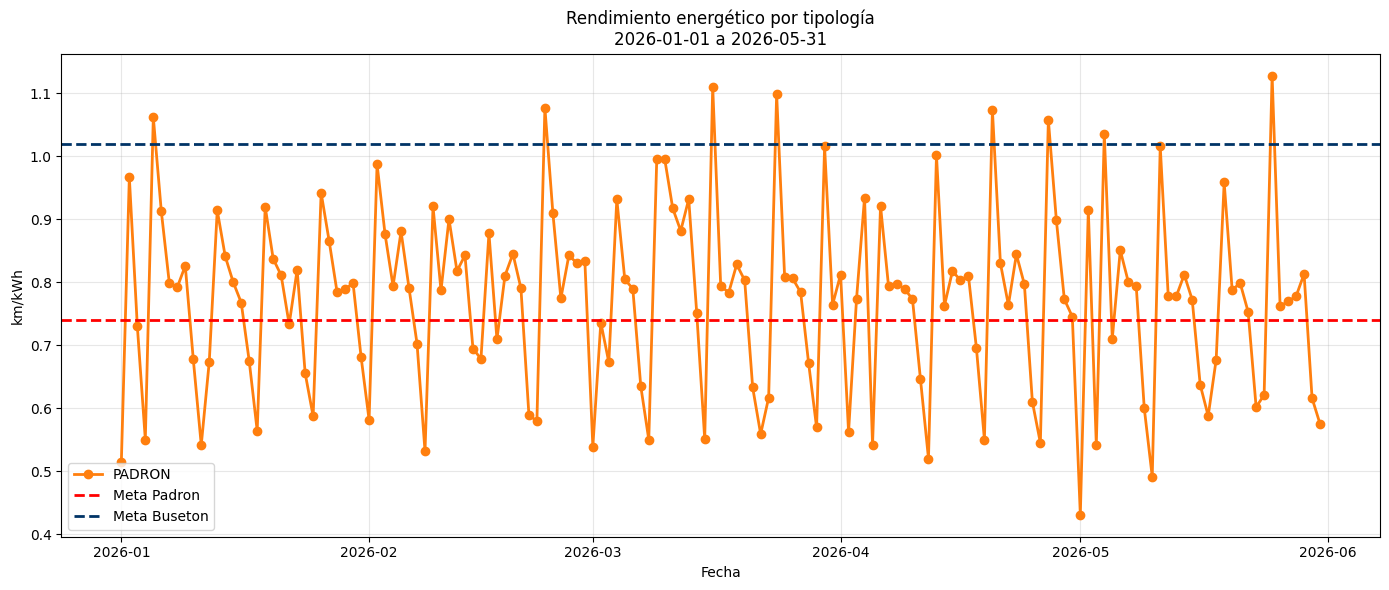

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

colores = {
    "BUSETON": "#1f77b4",  # azul
    "PADRON": "#ff7f0e"    # naranja
}

for tipologia in grafica_df["Tipologia"].unique():

    datos = grafica_df[
        grafica_df["Tipologia"] == tipologia
    ].sort_values("Fecha_Km")

    plt.plot(
        datos["Fecha_Km"],
        datos["Km_kWh"],
        marker="o",
        linewidth=2,
        color=colores.get(tipologia, "gray"),
        label=tipologia
    )

plt.axhline(
    y=0.74,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Meta Padron"
)

plt.axhline(
    y=1.02,
    color="#003366",
    linestyle="--",
    linewidth=2,
    label="Meta Buseton"
)

plt.title(
    f"Rendimiento energético por tipología\n{FECHA_INICIO} a {FECHA_FIN}"
)

plt.xlabel("Fecha")
plt.ylabel("km/kWh")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

## GRAFICO RENDIMIENTO GENERAL TODOS LOS AÑOS TODAS LAS TIPOLOGIAS

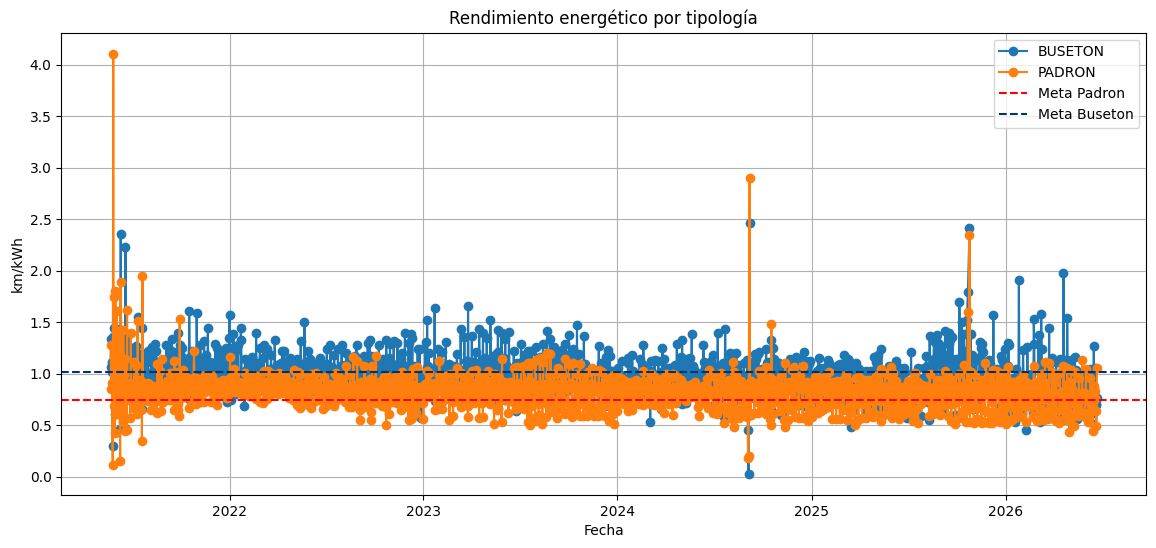

In [ ]:


import matplotlib.pyplot as plt


plt.figure(figsize=(14,6))

colores = {
    "BUSETON": "#1f77b4",  # azul
    "PADRON": "#ff7f0e"    # naranja
}

for tipologia in rendimiento_tipologia["Tipologia"].unique():
    datos = rendimiento_tipologia[
        rendimiento_tipologia["Tipologia"] == tipologia
    ]

    plt.plot(
        datos["Fecha_Km"],
        datos["Km_kWh"],
        marker="o",
        label=tipologia
    )

plt.axhline(y=0.74, color="red", linestyle="--", label="Meta Padron")
plt.axhline(y=1.02, color="#003366", linestyle="--", label="Meta Buseton")

plt.title("Rendimiento energético por tipología")
plt.xlabel("Fecha")
plt.ylabel("km/kWh")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parámetros de consulta
TIPOLOGIA = "PADRON"        # Opciones: "PADRON", "BUSETON", "TODAS"
FECHA_INICIO = "2025-05-22"
FECHA_FIN = "2026-05-31"

# Asegurar valores numéricos
resultado["Km"] = pd.to_numeric(resultado["Km"], errors="coerce")
resultado["Kwh"] = pd.to_numeric(resultado["Kwh"], errors="coerce")
resultado["Fecha_Km"] = pd.to_datetime(resultado["Fecha_Km"], errors="coerce")

# Filtrar registros válidos
df_valido = resultado[
    (resultado["Km"] > 0) &
    (resultado["Kwh"] > 0)
].copy()

# Filtrar por tipología
if TIPOLOGIA != "TODAS":
    df_valido = df_valido[
        df_valido["Tipologia"] == TIPOLOGIA
    ]

# Filtrar por fechas
df_valido = df_valido[
    (df_valido["Fecha_Km"] >= pd.to_datetime(FECHA_INICIO)) &
    (df_valido["Fecha_Km"] <= pd.to_datetime(FECHA_FIN))
]

# Rendimiento diario
rendimiento_diario = (
    df_valido
    .groupby("Fecha_Km", as_index=False)
    .agg(
        Km_total=("Km", "sum"),
        Kwh_total=("Kwh", "sum"),
        Vehiculos=("ID", "nunique")
    )
)

rendimiento_diario["Km_kWh_flota"] = (
    rendimiento_diario["Km_total"] / rendimiento_diario["Kwh_total"]
)

display(rendimiento_diario.head())

,Fecha_Km,Km_total,Kwh_total,Vehiculos,Km_kWh_flota
0,2025-05-22,21996.0,25276.34,112,0.870221
1,2025-05-23,21734.0,26347.21,112,0.824907
2,2025-05-24,16132.0,23597.60,101,0.683629
3,2025-05-25,10737.0,17378.73,76,0.617824
4,2025-05-26,12436.0,12611.22,65,0.986106


In [ ]:
from google.colab import files

nombre_archivo = f"rendimiento_{TIPOLOGIA}_{FECHA_INICIO}_{FECHA_FIN}.csv"

rendimiento_diario.to_csv(nombre_archivo, index=False, encoding="utf-8-sig")

files.download(nombre_archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## CALCULOS ESTADISTICOS

In [ ]:
# PARAMETROS

FECHA_INICIO = "2026-01-15"
FECHA_FIN = "2026-01-15"

# Filtrar periodo
df_estadistico = resultado.copy()

df_estadistico = df_estadistico[
    (df_estadistico["Fecha_Km"] >= pd.to_datetime(FECHA_INICIO)) &
    (df_estadistico["Fecha_Km"] <= pd.to_datetime(FECHA_FIN))
]

df_estadistico = df_estadistico[
    (df_estadistico["Km"] > 0) &
    (df_estadistico["Kwh"] > 0)
]

# Rendimiento individual
df_estadistico["Km_kWh"] = (
    df_estadistico["Km"] /
    df_estadistico["Kwh"]
)

# Media por tipología
media_tipologia = (
    df_estadistico
    .groupby("Tipologia")
    .agg(
        Media=("Km_kWh","mean"),
        Mediana=("Km_kWh","median"),
        DesvStd=("Km_kWh","std"),
        Minimo=("Km_kWh","min"),
        Maximo=("Km_kWh","max"),
        Observaciones=("Km_kWh","count")
    )
    .reset_index()
)

display(media_tipologia)

,Tipologia,Media,Mediana,DesvStd,Minimo,Maximo,Observaciones
0,BUSETON,1.048918,0.915749,0.457357,0.511310,1.883919,12
1,PADRON,0.846900,0.808243,0.332217,0.004906,2.308641,108


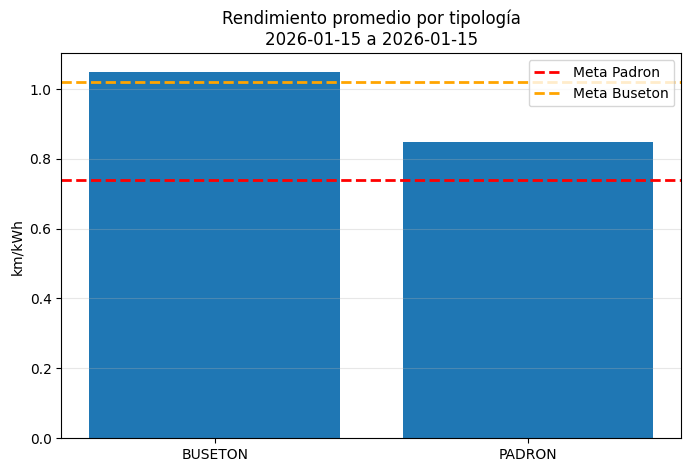

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    media_tipologia["Tipologia"],
    media_tipologia["Media"]
)

# Metas
plt.axhline(
    y=0.74,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Meta Padron"
)

plt.axhline(
    y=1.02,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Meta Buseton"
)

plt.ylabel("km/kWh")
plt.title(
    f"Rendimiento promedio por tipología\n{FECHA_INICIO} a {FECHA_FIN}"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()